<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Trees 1: Classification by Partition

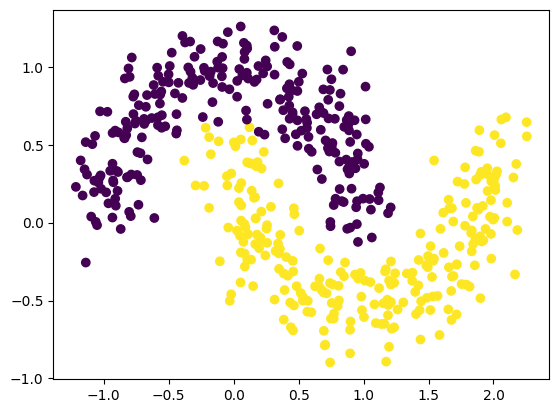

In [1]:
import numpy as np
from sklearn import metrics, inspection, datasets
from matplotlib import pyplot as plt

x_data, y_data = datasets.make_moons(n_samples=500, noise=0.15)

plt.scatter(x_data[:, 0], x_data[:, 1], c=y_data)
plt.show()

In [2]:
def leaf_gini_impurity(leaf_ys):
    if len(leaf_ys) == 0:
        return 0
    else:
        return 1 - (sum(leaf_ys==0)/len(leaf_ys))**2 - (sum(leaf_ys==1)/len(leaf_ys))**2

def weighted_gini_impurity(left_ys, right_ys):
    total = len(left_ys) + len(right_ys)
    left_leaf = leaf_gini_impurity(left_ys) * len(left_ys)/total
    right_leaf = leaf_gini_impurity(right_ys) * len(right_ys)/total
    return left_leaf + right_leaf

def gini_impurity(x_data, y_data, axis, threshold):
    # The axis argument should be 0 or 1
    # The threshold should be a real valued number
    left_mask = x_data[:, axis] <= threshold
    right_mask = x_data[:, axis] > threshold
    return weighted_gini_impurity(y_data[left_mask], y_data[right_mask])

#sample way to use this function
gini_impurity(x_data, y_data, axis=1, threshold=0.0)

np.float64(0.2833054945054944)

In [3]:
# code from code cell 2 (given)
def leaf_gini_impurity(leaf_ys):
    if len(leaf_ys) == 0:
        return 0
    else:
        return 1 - (sum(leaf_ys==0)/len(leaf_ys))**2 - (sum(leaf_ys==1)/len(leaf_ys))**2

def weighted_gini_impurity(left_ys, right_ys):
    total = len(left_ys) + len(right_ys)
    left_leaf = leaf_gini_impurity(left_ys) * len(left_ys)/total
    right_leaf = leaf_gini_impurity(right_ys) * len(right_ys)/total
    return left_leaf + right_leaf

# this function will directly solve this question:
def gini_impurity(x_data, y_data, axis, threshold):
    # The axis argument should be 0 or 1
    # The threshold should be a real valued number
    left_mask = x_data[:, axis] <= threshold
    right_mask = x_data[:, axis] > threshold
    return weighted_gini_impurity(y_data[left_mask], y_data[right_mask])

# Here's a sample way to use this function
# gini_impurity(x_data, y_data, axis=1, threshold=0.0)

# CS110 tree
def split_finder_function(x, y):
    axis_best = None
    threshold_value = None
    lower_gini_value = np.inf

    for axis in [0, 1]:
        i = np.unique(x[:, axis])
        for j in i:
            k = gini_impurity(x, y, axis=axis, threshold = j)
            if k < lower_gini_value:
                lower_gini_value = k
                axis_best = axis
                threshold_value = j
    return axis_best, threshold_value, lower_gini_value

# the same format as gini_impurity function
root_axis, root_threshold, root_gini_impurity = split_finder_function(x_data, y_data)
# printing the axis and threshold value of the root split
print(f"Root split: axis={root_axis}, threshold={root_threshold}, weighted_gini={root_gini_impurity}", '\n')
# getting the leaves for root
root_left_mask = x_data[:, root_axis] <= root_threshold
root_right_mask = x_data[:, root_axis] > root_threshold
# getting the leaves for each of the two halves
x_left_leaf, y_left_leaf = x_data[root_left_mask], y_data[root_left_mask]
x_right_leaf, y_right_leaf = x_data[root_right_mask], y_data[root_right_mask]
# getting best split for each of the two halves
left_axis, left_threshold, left_gini_impurity = split_finder_function(x_left_leaf, y_left_leaf)
right_axis, right_threshold, right_gini_impurity = split_finder_function(x_right_leaf, y_right_leaf)
# printing the axis and threshold value of each of these two splits
print(f"Left child best split:  axis={left_axis}, threshold={left_threshold}, weighted_gini={left_gini_impurity}", '\n')
print(f"Right child best split: axis={right_axis}, threshold={right_threshold}, weighted_gini={right_gini_impurity}")

Root split: axis=1, threshold=0.09498287909088636, weighted_gini=0.2687134066444411 

Left child best split:  axis=0, threshold=-0.6109654121479005, weighted_gini=0.08455639632319334 

Right child best split: axis=0, threshold=1.2086669174917901, weighted_gini=0.18936843179267426
